## AIM: Here we are going to SLM preprocessing steps

## DOC: 04/Aug/2026

## Author: Shalu Singh

### STAGE-1.1) DATA Preparation & Sampling

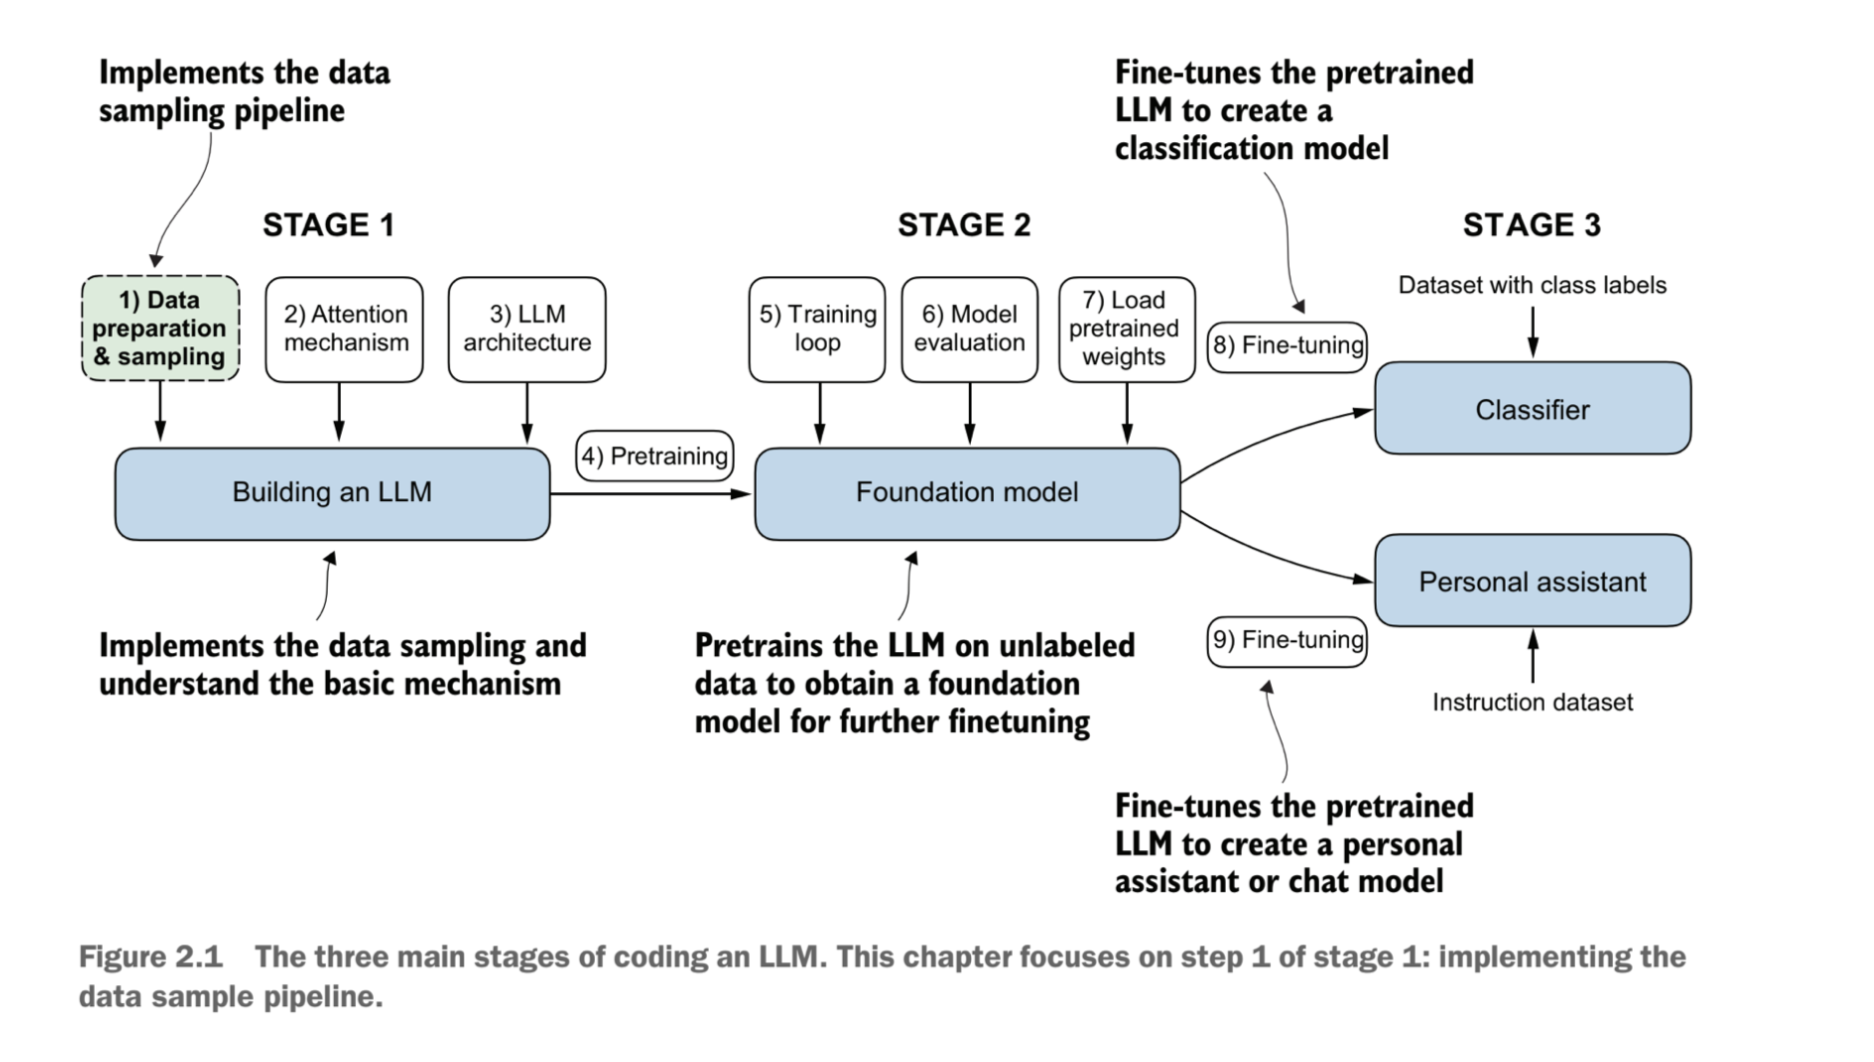

# Text Preprocessing Steps

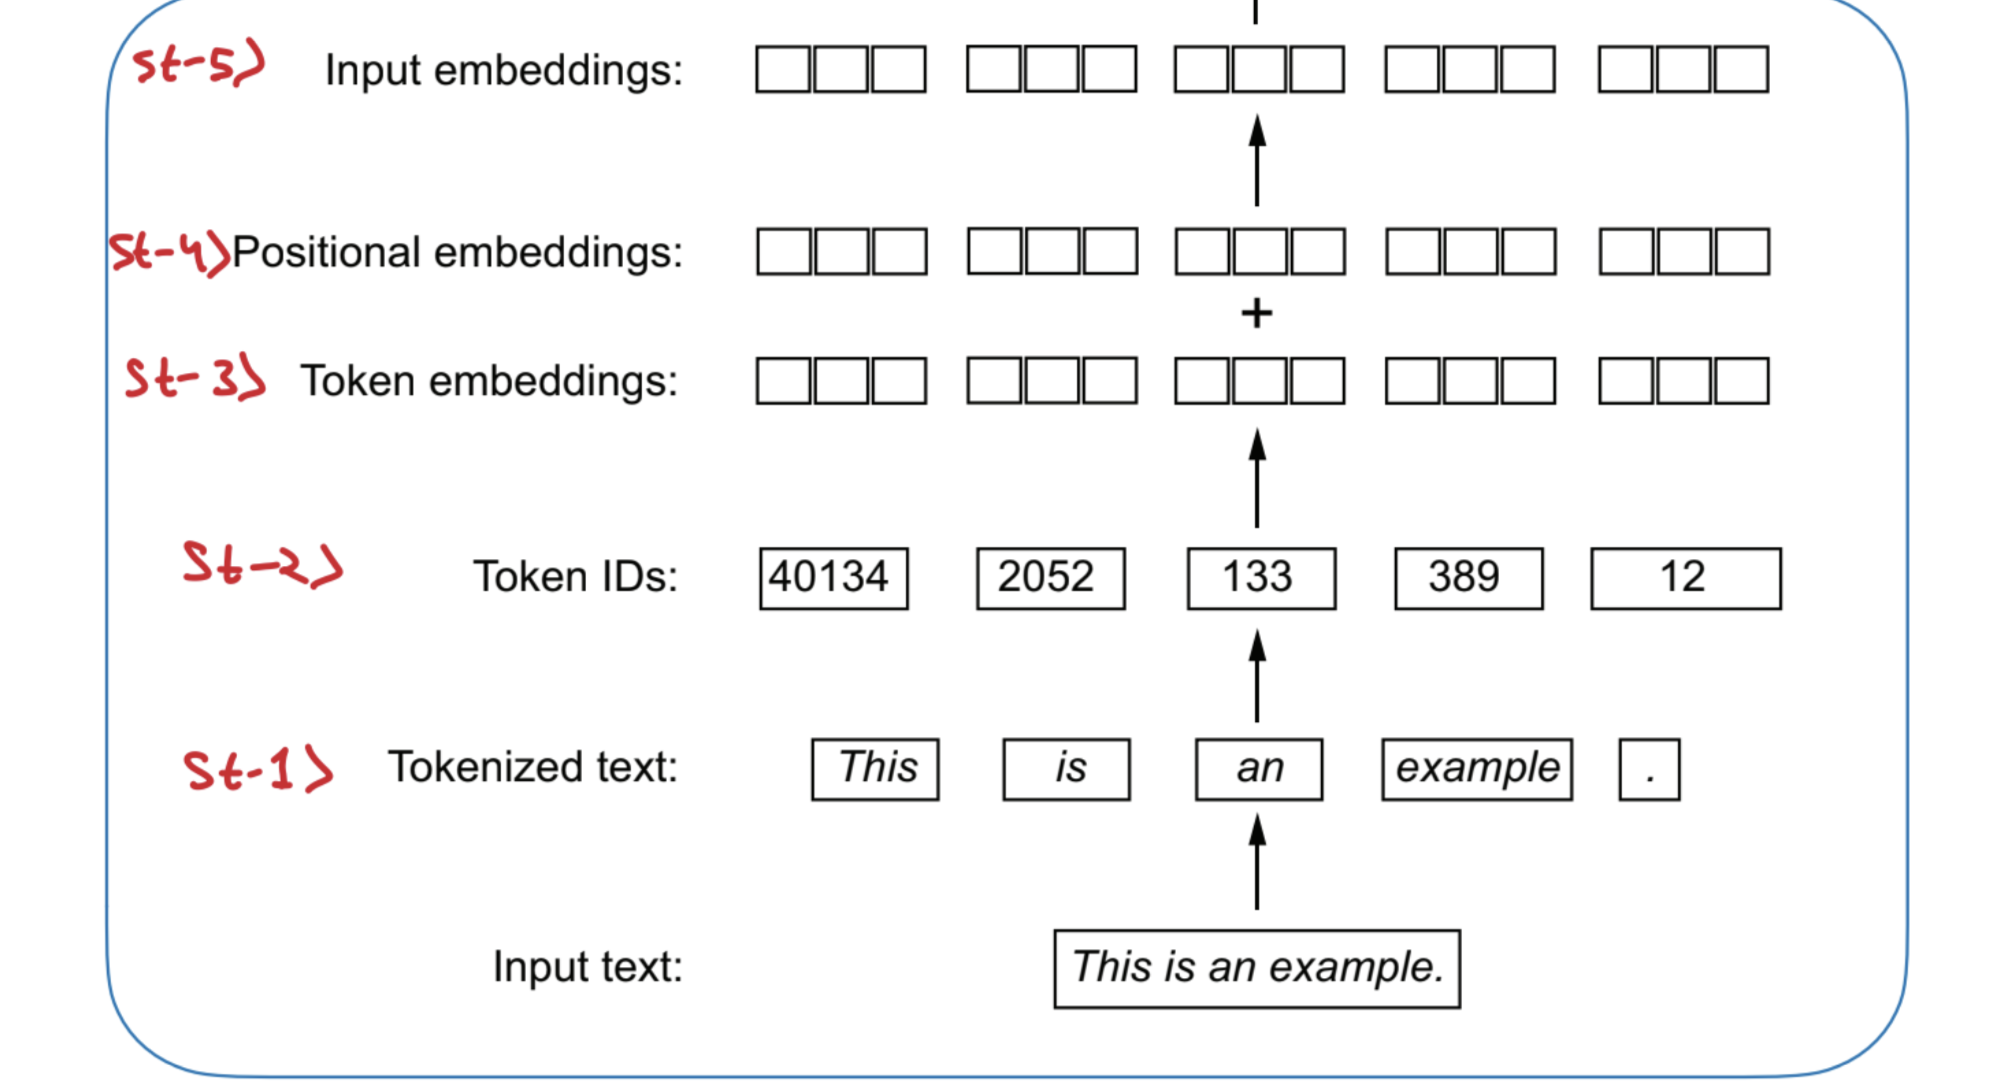

#### Dataset

In [64]:
# Downloading the short story text dataset to work on
# import urllib
# url = ("https://raw.githubusercontent.com/rasbt/"
# "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
# "the-verdict.txt")

# file_path = "the_verdict.txt"
# urllib.request.urlretrieve(url,file_path)


# read the file
with open('/kaggle/working/the_verdict.txt','r',encoding = 'utf-8') as f:
    raw_text = f.read()

print("Total number of Characters:",len(raw_text))
print("Sample Text:",raw_text[:100])

Total number of Characters: 20479
Sample Text: I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no g


### Step-1) Tokenizing Text

- Here we split the input text into `individual tokens`
- Tokens are either `words,subwords or characters`

#### ``Experiment 1.1) How can we best split this text to obtain a list of tokens?``

In [65]:
# Exp-1) Spliting text using regular expression
import re
text = "How are you? This is a smaple text."
tokens = re.split(r'(\s)',text)  # split on whitespaces
print(tokens)

['How', ' ', 'are', ' ', 'you?', ' ', 'This', ' ', 'is', ' ', 'a', ' ', 'smaple', ' ', 'text.']


##### Observation of Exp-1)
- As you can see in the ouput special characters like `?` , `.` are still attached to the words so we need to split the special character and make it as seperate individual token

In [66]:
# Exp-2) Modifying the regular experession to split on whitespaces(/s),?,.
tokens = re.split(r'([?.]|\s)',text)
print(tokens)

['How', ' ', 'are', ' ', 'you', '?', '', ' ', 'This', ' ', 'is', ' ', 'a', ' ', 'smaple', ' ', 'text', '.', '']


##### Observation of Exp-2)
- Now special characters are also sperate tokens but there are redudant whitespaces in tokens

In [67]:
# Exp-3) Removing whitespaces
tokens = re.split(r"([?.]|\s)",text)
tokens = [token for token in tokens if token.strip()]
print(tokens)

['How', 'are', 'you', '?', 'This', 'is', 'a', 'smaple', 'text', '.']


##### Observation of Exp-3)
- Now the tokens list doesn't have any whitespaces.
- Removing or keeping whitespaces totally depends on use cases removing whitespaces reduce the `computational resources` however keeping whitespace `preserve the structure of the text` which is important for LLM

In [68]:
# Exp-4) Applying the basic tokenization to complete dataset
tokens = re.split(r'([?.] |\s)',raw_text)
tokens = [token for token in tokens if token.strip()]  # removing white spaces
print("Total number of tokens:",len(tokens))
print("Sample Tokens:",tokens[:5])

Total number of tokens: 3768
Sample Tokens: ['I', 'HAD', 'always', 'thought', 'Jack']


##### Observation of Exp-4)
- There are `3768` tokens in the datset
- In order to distinguish between proper nouns and common nouns, understand sentence structure, and learn the to generate text with proper captalization we reffrain from making all the tokens to lower case in order to preserve the structure of the data.

### Step-2) Converting tokens into Token IDs

- Here first we create the `vocabulary of training data`
- The vocabulary contains `all unique tokens in training set and is usually sorted alphabetically`
- Each unique token is mapped to a unique integer called `Token ID`
  
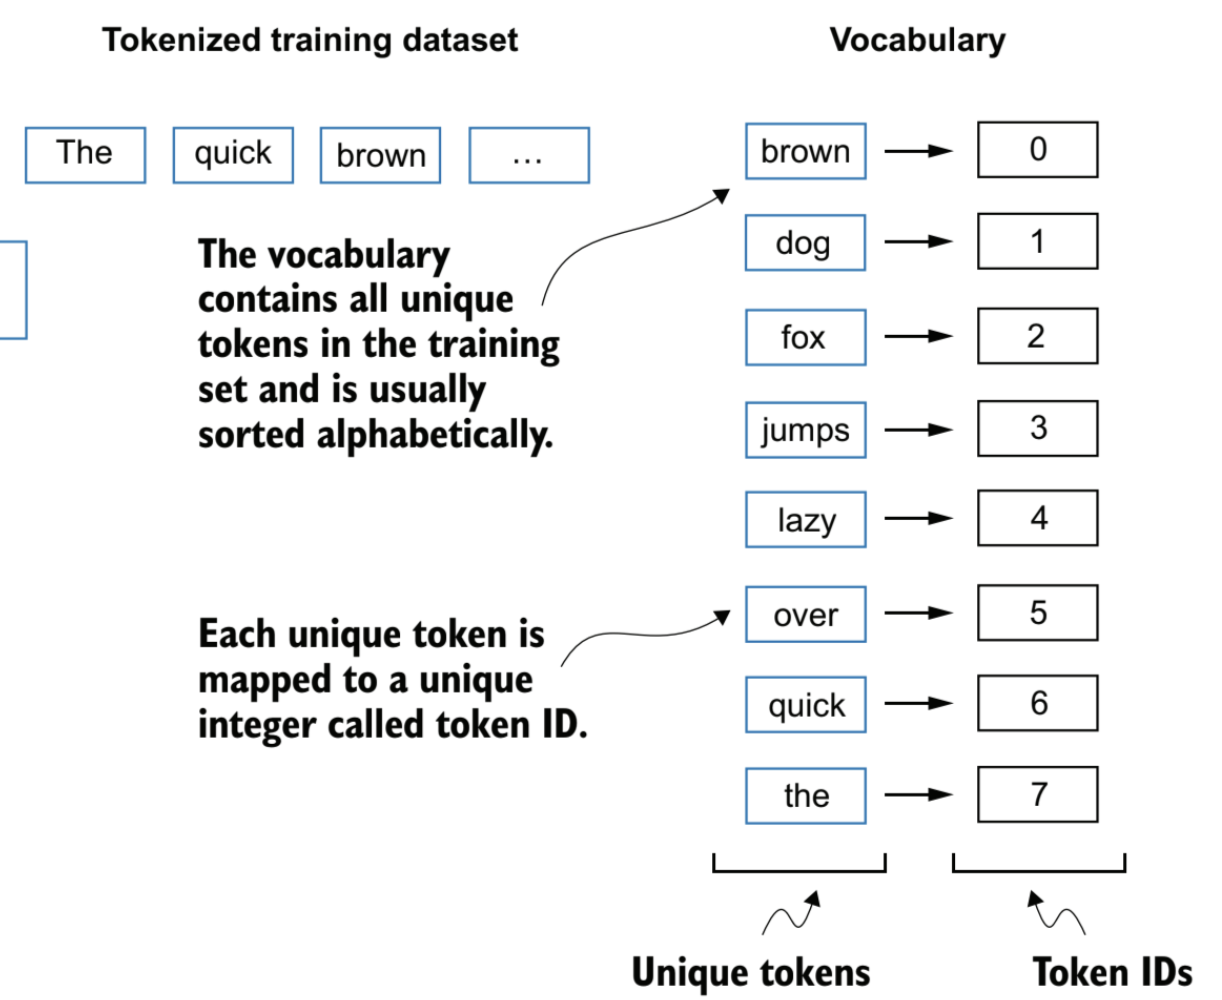

##### Step-2.1) Creating Vocabulary

In [69]:
# Creating a vocabulary for the training dataset

tokens = list(sorted(set(tokens)))  # Unique tokens sorted alphabetically 
vocab = {token:token_id for token_id,token in enumerate(tokens)}
print("Vocabulary size:",len(vocab))
print("Sample of Vocabulary")
for token,id in vocab.items():
    if id > 5:
        break
    print(token,id)

Vocabulary size: 1437
Sample of Vocabulary
"Ah, 0
"Ah--I 1
"Be 2
"By 3
"Come 4
"Destroyed 5


#### Step-2.2) Implementing a simple text tokenizer
- A tokenizer class consist of `encoder` and `decoder` method
- `Encoder` method split the text into tokens and carries out `string-to-integer mapping` to produce `token id` via `vocabulary`

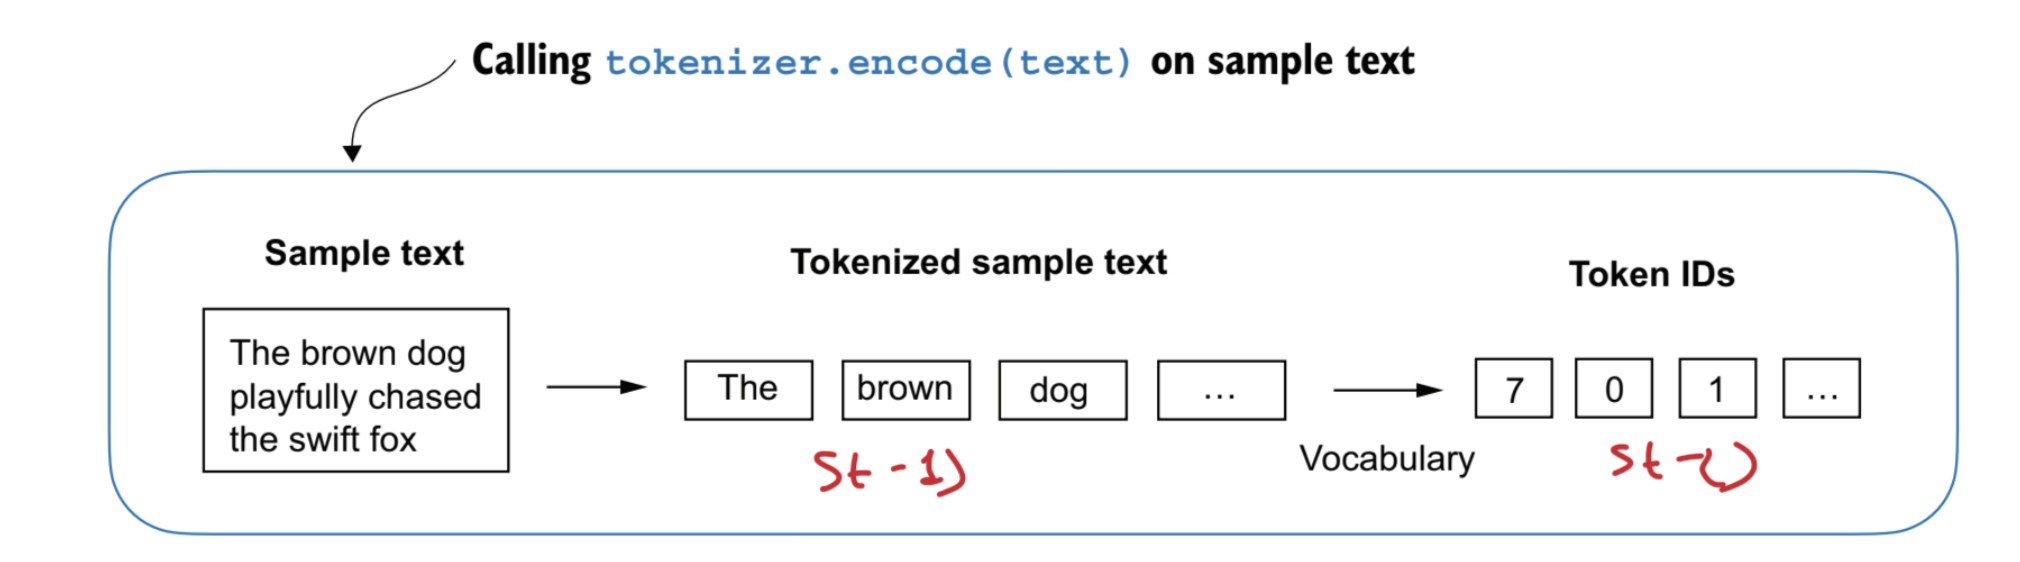

- `Decoder` method carries out `integer-to-string mapping` to convert `token ID` back to text

  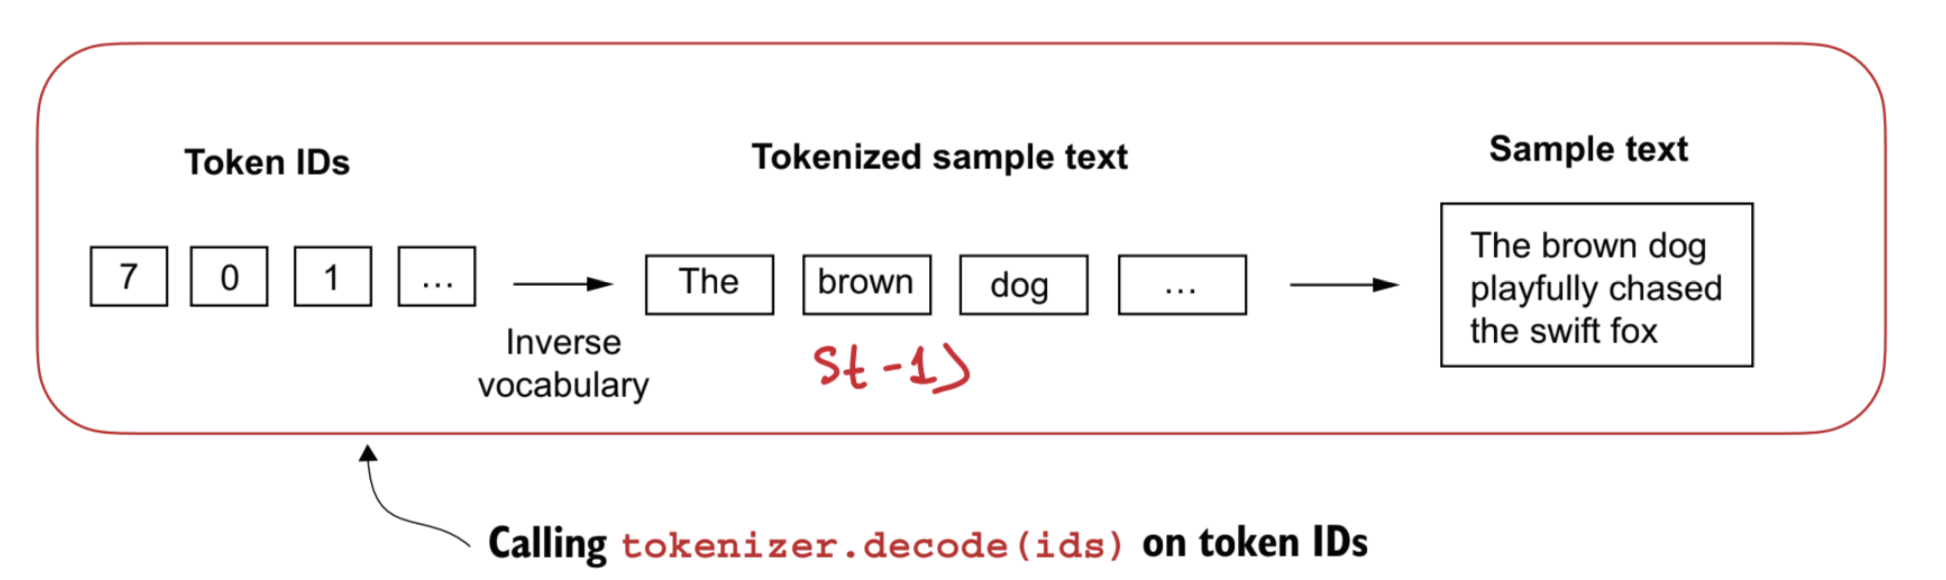

In [70]:
# Implementing SimpleTextTokenizerV1 class

class SimpleTextTokenizerV1():
    def __init__(self,vocab):
        self.vocab = vocab   # stores vocabulary as class attribute to access in encode and decode method
        self.int_to_str = {token_id:token for token,token_id in self.vocab.items()}  # create a reverse vocabulary that maps token IDs back to tokens

    def encode(self,text):   # Process input text into token IDs
        tokens = re.split(r'([?.] |\s)',text)
        tokens = [token for token in tokens if token.strip()]  # Removing whiteSpaces
        ids = [self.vocab[token] for token in tokens]  # Tokens Ids
        return ids

    def decode(self,token_ids): # Convert tokens IDs back into text
        tokens = [self.int_to_str[token_id] for token_id in token_ids]
        text = " ".join(tokens)
        return text

In [71]:
tokenizerv1 = SimpleTextTokenizerV1(vocab)
text = "the last he painted, you know,"
token_ids = tokenizerv1.encode(text)  # getting token_ids
tokens = tokenizerv1.decode(token_ids) # getting tokens back from token_ids
print("Tokens IDs:",token_ids)
print("Tokens:",tokens)

Tokens IDs: [1251, 783, 671, 971, 1429, 774]
Tokens: the last he painted, you know,


#### `Experiment 2.1) Tokenizing unknown words`

In [72]:
# Exp 2.1) Tokenizing uknown words
text = "How are you?"
token_ids = tokenizerv1.encode(text)

KeyError: 'How'

##### Observation of Exp-2.1)

- Since There was no 'How' word token in the vocabulary it's throwing an error
- This highlights the need to consider `large and diverse training sets` to extend the vocabulary when working on LLMs.

### Step-2.3) Adding Special Tokens

- These special tokens can include markers for unknown words and document boundaries,
- `<|unk|>` token represent new and uknown word that were not a part of training data and thus not part of the existing vocabulary.
- `<|endoftext|>` token is use to seperate two unrelated text source.

In [ ]:
# A simple text tokenizer that handles unknown words

# Creating Vocabulary 
all_tokens = re.split(r'([?.]|\s)',raw_text)
preprocessed_tokens = sorted(set(all_tokens))
preprocessed_tokens.extend(['<|unk|>','<|endoftext|>'])
vocab = {token:token_id for token_id,token in enumerate(preprocessed_tokens)}
print("Vocabulary size:",len(vocab))
print("Last 5 items of vocabulary:",list(vocab.items())[-5:])


In [ ]:
re.split(r'([?.]|\s)',"How is the tea?")

In [ ]:
# Creating a Tokenizer Class
class SimpleTextTokenizerV2():
    def __init__(self,vocab):
        self.vocab = vocab
        self.int_to_str = {token_id:token for token,token_id in self.vocab.items()}

    def encode(self,text):
        tokens = re.split(r"([?.]|\s)",text)
        tokens = [token if token in self.vocab else '<|unk|>' for token in tokens] # add unknown token if that token is not is vocab
        token_ids = [self.vocab[token] for token in tokens]
        return token_ids

    def decode(self,token_ids):
        tokens = [self.int_to_str[token_id] for token_id in token_ids]
        text = "".join(tokens)
        return text

In [ ]:
tokenizerv2 = SimpleTextTokenizerV2(vocab)
text = "Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace."
token_ids = tokenizerv2.encode(text)
decoded_text = tokenizerv2.decode(token_ids)
print("Original Text:",text)
print("Token IDs:",token_ids)
print("Decoded Text:",decoded_text)


### Step-2.4) Byte Pair Encoding (BPE)
- BPE tokenizer break down `unknown words into subwords and individual characters`
- This way, a BPE tokenizer can parse any word and doesn’t need to replace unknown words with special tokens, such as <|unk|>.
- The BPE tokenizer was used to train LLMs such as `GPT-2, GPT-3`, and the original model used in ChatGPT.

#### How BPE Algorithm works?

- BPE builds its vocabulary by `iteratively merging frequent characters into sub-
words and frequent subwords into words`.
- For example, BPE starts with adding all individual single characters to its vocabulary (“a,” “b,” etc.). In the next stage, it merges character combinations that frequently occur together into subwords. For example, “d” and “e” may be merged into the subword “de,” which is common in many English words like “define,” “depend,” “made,” and “hidden.”
- The merges are determined by a frequency cutoff.

In [ ]:
# To use BPE Algorithm use tiktoken
import tiktoken
tiktoken.__version__

In [ ]:
# getting vocab size of all available tokeinzer
for name in tiktoken.list_encoding_names():
    tok = tiktoken.get_encoding(name)
    print(f"{name} | vocab size: {tok.n_vocab}")

#### `Experiment 2.4) Experiment with different tokenizers available in tiktoken`

# FINAL TOKENIZER: BPE GPT2

In [ ]:
# Step-1) Initiate the BPE tokenizer form tiktoken
gpt2_tokenizer = tiktoken.get_encoding('gpt2')   # gpt2 tokenizer
gpt2_vocabsize = gpt2_tokenizer.n_vocab # return the vocabulary size
text = "How are you?"  # text sample
token_ids = gpt2_tokenizer.encode(text,allowed_special = {'<|endoftext|>'})  # encoding 
decoded_text = gpt2_tokenizer.decode(token_ids)
print("GPT-2 vocabulary size:",gpt2_vocabsize)
print("Original Text:",text)
print("Token IDs:",token_ids)
print("Decoded Text:",decoded_text)

### Step-3) Data Sampling with a Sliding Window

- The next step in creating the `input–target pairs` required for training an LLM.
- One of the easiest and most intuitive ways to create the input–target pairs for the next-word prediction task is to create two variables, x and y, where x contains the input tokens and y contains the targets, which are the `inputs shifted by 1`
  
  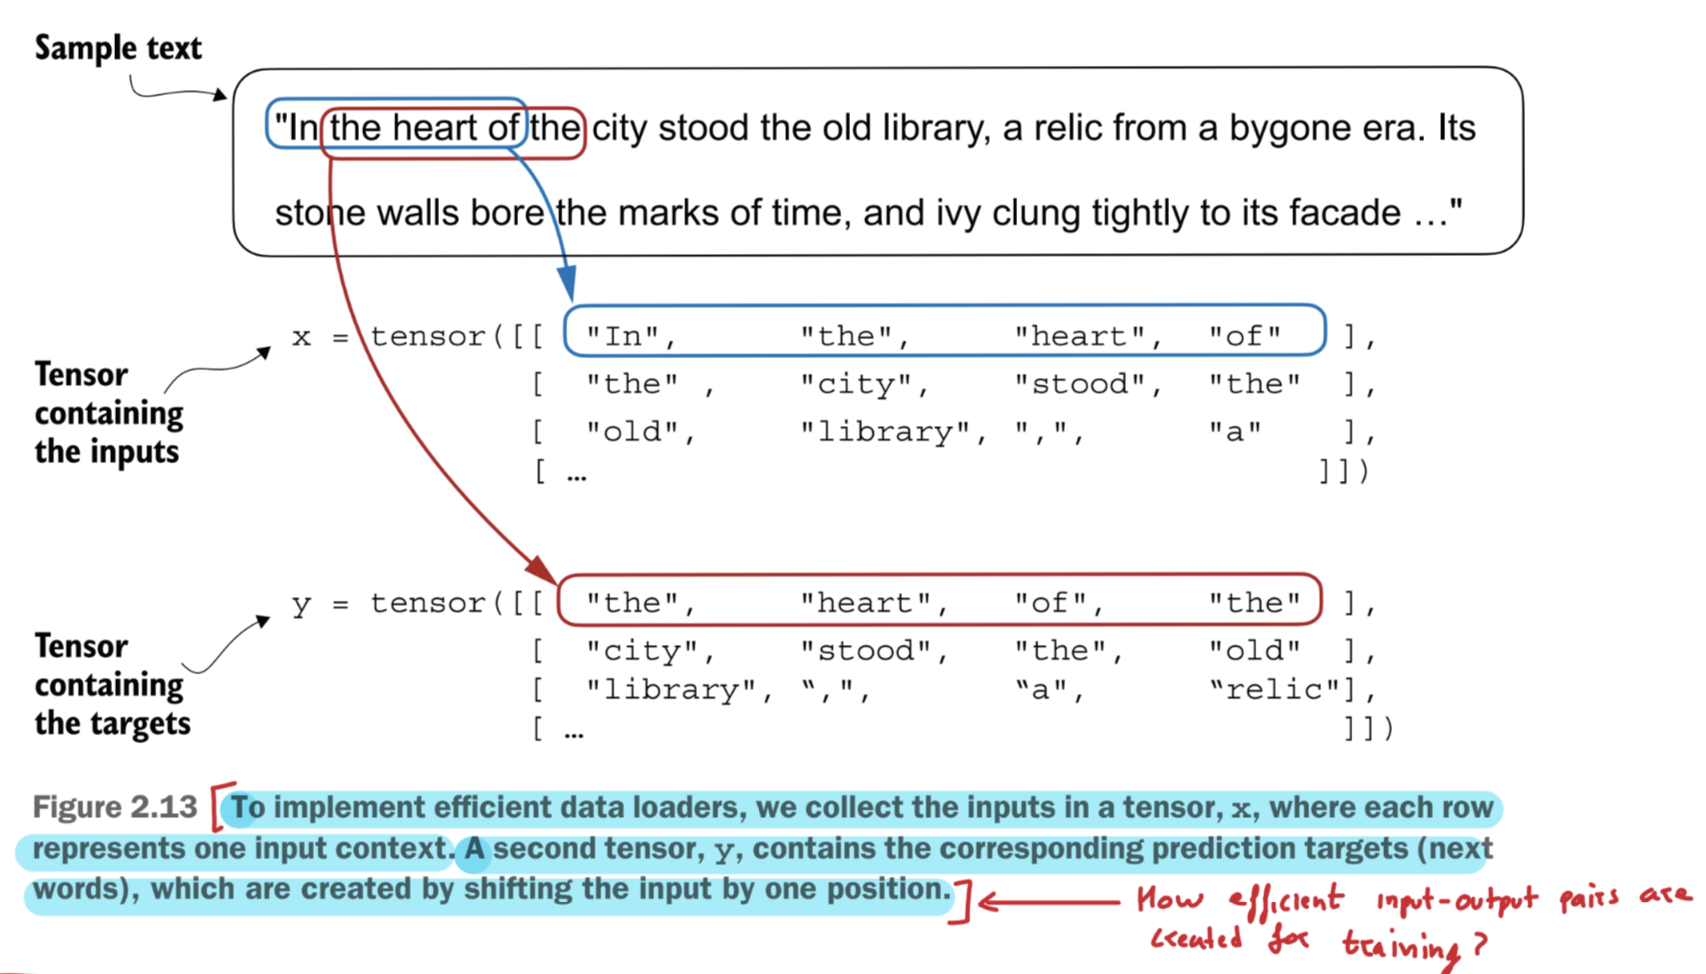
  

In [73]:
# Converting the raw_text of verdict to token IDs
verdict_token_ids = gpt2_tokenizer.encode(raw_text,allowed_special = {'<|endoftext|>'})
print("Token counts:",len(verdict_token_ids))

Token counts: 5145


In [74]:
# Creating input-target pair
context_length = 5   # size of context/input window
for i in range(1,context_length+1):
    x = verdict_token_ids[:i]  # input tokens ---> sliding window
    y = verdict_token_ids[i]   # ouput token
    print(f"{x} ---> {y} | {gpt2_tokenizer.decode(x)} ---> {gpt2_tokenizer.decode([y])}")
    

[40] ---> 367 | I --->  H
[40, 367] ---> 2885 | I H ---> AD
[40, 367, 2885] ---> 1464 | I HAD --->  always
[40, 367, 2885, 1464] ---> 1807 | I HAD always --->  thought
[40, 367, 2885, 1464, 1807] ---> 3619 | I HAD always thought --->  Jack


#### Step-3.1) Implementing the Efficient Dataloader using Pytorch `Dataset` and `DataLoader` class

#### Step-3.1.1) A `Dataset class` for batched inputs and targets

In [75]:
# Implementing Dataset class
import torch
from torch.utils.data import Dataset

class GPTDatasetV1(Dataset):
    def __init__(self,text,tokenizer,context_length,stride):  

        '''
        Aug:
        1) stride: The stride setting dictates the number of positions the inputs shift across batches, 
        emulating a sliding window approach
        '''
        self.input_ids = [] # store the input token IDs
        self.target_ids = []  # strore the output token IDs

        token_ids = tokenizer.encode(text,allowed_special = {'<|endoftext|>'}) # encoding
        total_tokens = len(token_ids)  # total no. of training dataset tokens
        
        for i in range(0,total_tokens - context_length,stride):  # Uses a sliding window to chunk the text into sequences of context_length size
            x = token_ids[i:i+context_length]  # input --> sliding window approach
            y = token_ids[i+1:i+1+context_length] # target ---> sliding window shifted by position 1
            self.input_ids.append(torch.tensor(x))  # converted input to pytorch tensor
            self.target_ids.append(torch.tensor(y)) # converted target to pytorch tensor

    def __len__(self):   # returns the total no. of rows in dataset
        return len(self.input_ids)

    def __getitem__(self,idx): # returns a single row from the dataset
        return self.input_ids[idx],self.target_ids[idx]  
        

In [76]:
dataset = GPTDatasetV1(raw_text,gpt2_tokenizer,512,256)
print("Size of input:",len(dataset)) # 19 batchs of input-target pair with context window of 512 and stride of 256 is created

Size of input: 19


##### Observation of Step-3.1.1

- GPTDatasetV1 class is based on the PyTorch `Dataset class` and defines how individual rows are fetched from the dataset,
- Each row consists of a number of token IDs (`based on a context_length`) assigned to an input_chunk tensor.
- The target_chunk tensor contains the corresponding targets.

#### Step-3.1.2) A `DataLoader class` to generate batches with input-with pairs

In [77]:
from torch.utils.data import DataLoader

def create_dataloader_v1(text,context_length,stride,batch_size,shuffle = True,drop_last = True,num_workers = 0):
    tokenizer = tiktoken.get_encoding("gpt2") # Initializing tokenzier
    dataset = GPTDatasetV1(text,tokenizer,context_length,stride)  # Create Dataset
    dataloader = DataLoader(dataset = dataset,batch_size = batch_size,
                            shuffle = shuffle,drop_last = drop_last,  # drop_last = True , drop the last batch if it is shorter than the specified batch_size to prevent loss spikes during training
                            num_workers = num_workers) # num_workers define the no. of cpu process to use for preprocessing
    
    return dataloader  # return DataLoader class object
    

In [78]:
dataloader = create_dataloader_v1(text = raw_text,context_length = 512,
                                  stride = context_length,batch_size = 4)

dataloader_iter = iter(dataloader)  # convert the dataloader to python iterator to fetch next-batch using next function

first_batch = next(dataloader_iter)
second_batch = next(dataloader_iter)
print("Shape of input tensor:",first_batch[0].shape)
print("Shape of target tensor:",first_batch[1].shape)
    
print("First Batch Input:\n",first_batch[0])
print("First Batch Targets:\n",first_batch[0])

Shape of input tensor: torch.Size([4, 512])
Shape of target tensor: torch.Size([4, 512])
First Batch Input:
 tensor([[   82, 24357,  1871,  ...,  2366,  9662,   290],
        [  198,   198,  5779,  ...,    13,   764,   764],
        [14150,    62,   284,  ...,   616,  2951,  6348],
        [  287,  1936,  2431,  ...,    30,  4162,    11]])
First Batch Targets:
 tensor([[   82, 24357,  1871,  ...,  2366,  9662,   290],
        [  198,   198,  5779,  ...,    13,   764,   764],
        [14150,    62,   284,  ...,   616,  2951,  6348],
        [  287,  1936,  2431,  ...,    30,  4162,    11]])


#### ⚠️ NOTES:
- `Small` batch size requires `less memory` during training but leads to more `noisy model updates`.
- Avoide any `overlap` between batches since more overlap will lead to `overfittint` set `stride` equal to `context length` to avoid `overlap` across batches.

### `Experiment 3) Data loaders with different strides and context sizes`
- To develop more intuition for how the data loader works, try to run it with different settings such as max_length=2 and stride=2, and max_length=8 and stride=2.

### Step-4) Token Embeddings

- As a first step we must initialize the token embedding weights with random values.
- The shape of token embeddings is `vocab_size, embd_dim` where `vocab_size` is the size of vocanulary ` and `embd_dim` is the the dimensions of each embeddings.
- Embedding is basically a `lookup table` so so each row in `embedding weight matrix` corresponds to `unique token` in vocabulary
- In GPT like llm we `train` the embedding layer as the part of training cycle hence these embedding layer are `optimized on training data and specific task`.

In [79]:
# Creating a Embeeding layers
torch.manual_seed(42) # set the random seed for reproducibility
vocab_size = gpt2_tokenizer.n_vocab   # return the vocabulary size
embd_dim = 5
embedding_layer = torch.nn.Embedding(num_embeddings = vocab_size, embedding_dim = embd_dim)
print("Token Embedding shape:",embedding_layer)
print("Sample Embedding Weights:\n",embedding_layer.weight)

Token Embedding shape: Embedding(50257, 5)
Sample Embedding Weights:
 Parameter containing:
tensor([[ 1.9269,  1.4873,  0.9007, -2.1055,  0.6784],
        [-1.2345, -0.0431, -1.6047, -0.7521,  1.6487],
        [-0.3925, -1.4036, -0.7279, -0.5594, -0.7688],
        ...,
        [-0.6169,  0.2157,  1.6189, -0.3590, -0.2036],
        [-0.3122,  0.3795,  1.4710,  1.0481, -0.0447],
        [ 1.9770,  0.2566,  0.5854,  1.2571,  0.5588]], requires_grad=True)


In [80]:
# Applying the token embedding for testing
embedding_layer(torch.tensor([0])), embedding_layer(torch.tensor([2]))

(tensor([[ 1.9269,  1.4873,  0.9007, -2.1055,  0.6784]],
        grad_fn=<EmbeddingBackward0>),
 tensor([[-0.3925, -1.4036, -0.7279, -0.5594, -0.7688]],
        grad_fn=<EmbeddingBackward0>))

#### Observation:

- As you can see in the above output the 0 gives the 0th index row as ouput similary the 2 input gives the 2nd row as output.
- In other words, the embedding layer is essentially a `lookup operation` that retrieves rows from the embedding layer’s weight matrix via a token ID.

### Step-5) Encoding Word Positions

- A `shortcoming of LLMs` is that their `self-attention` mechanism `doesn’t have a notion of position` or order for the tokens within a sequence.
- The way the embedding layer works is that the `same token ID always gets mapped to the same vector representation`, regardless of where the token ID is positioned in the input sequence.

- The two broad categories of position-aware embeddings are:
  * *`Absolute Positional Embedding:`*
      - Absolute positional embeddings are directly associated with the `specific position in a sequence`.
      - For each position in a sequence a `unique` embedding is `added` to the token embedding to convey it's position.
      - OpenAI’s GPT models use `absolute positional embeddings` that are `optimized during the training process` rather than being fixed or predefined like the positional.         This optimization process is part of the model training itself.
        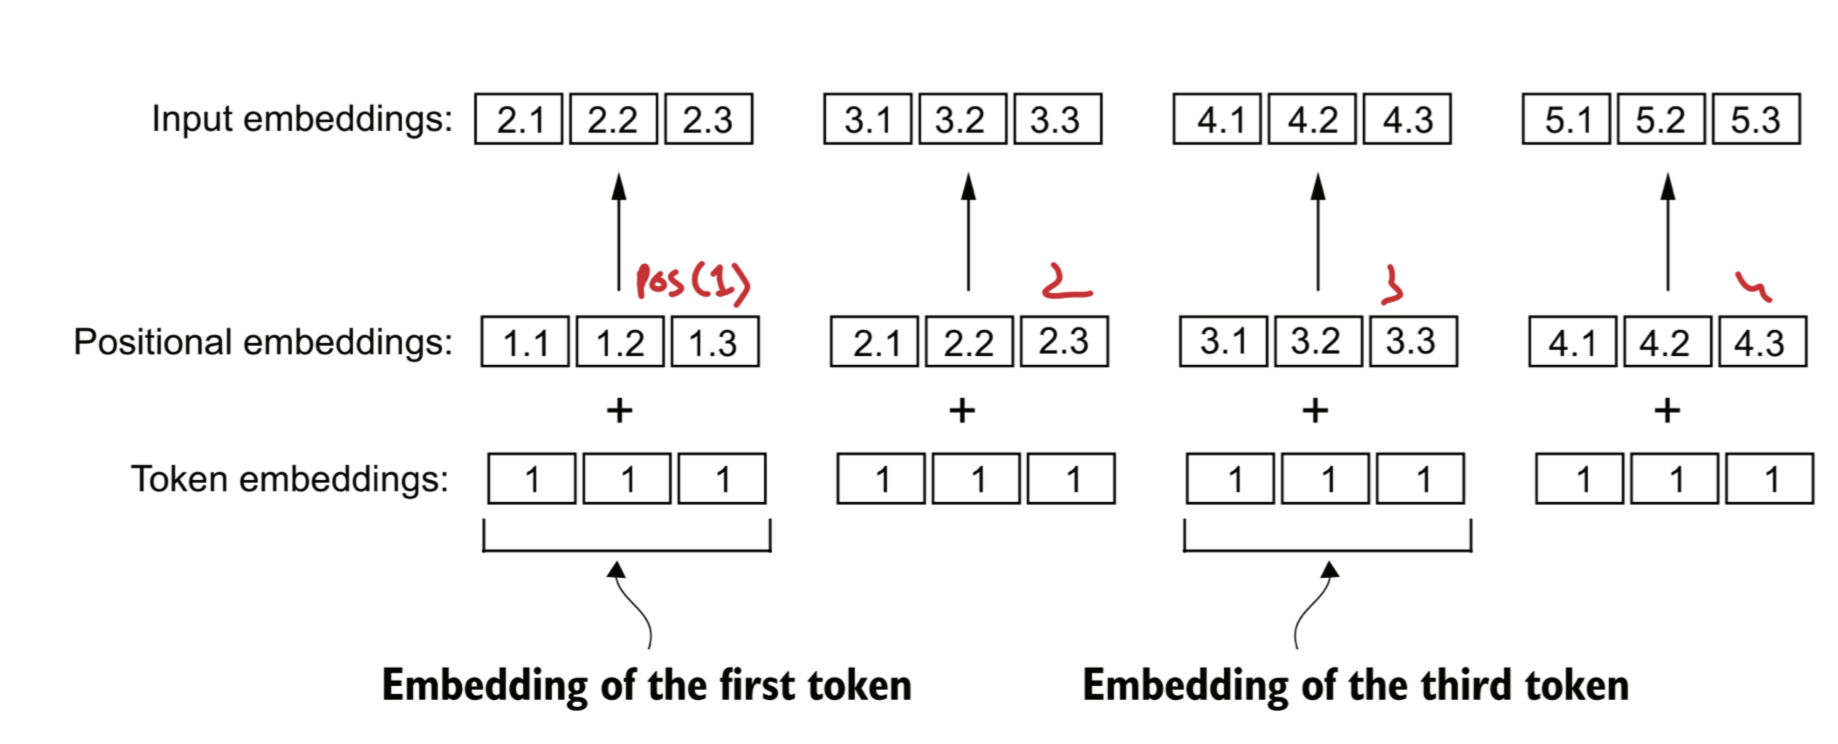


* *`Relative Positional Embedding:`*
     - The realtive positional embedding focuses on relative or `distance between tokens`.
     - This means that the model learn the relationships in terms of `how far apart` rather than `at which exact position`.
     - The advantage here is that model can generalize better to a `sequence of varying length` even if hasn't seen such length during training.
       
- Positional embeddings aim to `augment the capacity of LLMs to understand the order and relationships between tokens`, ensuring more accurate and
context-aware predictions.


*`Q.) What is the shape of positional embedding ?`*

- The shape of positional embedding matrix is **`(context_length,embd_dim)`**.


In [81]:
# Creating positional embedding layer
context_length = 512
embd_dim = 5
pos_embeddings = torch.nn.Embedding(num_embeddings = context_length, embedding_dim = embd_dim)
print("Positional Embedding shape:",pos_embeddings)
print("Positional Weight matrix:",pos_embeddings.weight)

Positional Embedding shape: Embedding(512, 5)
Positional Weight matrix: Parameter containing:
tensor([[ 0.3507,  0.5751, -0.0161, -1.9968, -0.5081],
        [-0.6773,  0.5732,  2.1682,  0.5195, -1.1126],
        [-0.9798,  0.6452, -0.3176,  1.9502,  0.9061],
        ...,
        [-0.3879, -0.0582, -0.9949,  0.6545, -0.2878],
        [-0.0468, -0.5846,  0.2476, -0.5218,  0.3465],
        [-0.6201, -0.6200,  0.0526, -1.2174,  2.7668]], requires_grad=True)


In [82]:
# Applying Absolute Positional Embedding
pos_embd = pos_embeddings(torch.arange(context_length))
print("Shape:",pos_embd.shape)
print(pos_embd)

Shape: torch.Size([512, 5])
tensor([[ 0.3507,  0.5751, -0.0161, -1.9968, -0.5081],
        [-0.6773,  0.5732,  2.1682,  0.5195, -1.1126],
        [-0.9798,  0.6452, -0.3176,  1.9502,  0.9061],
        ...,
        [-0.3879, -0.0582, -0.9949,  0.6545, -0.2878],
        [-0.0468, -0.5846,  0.2476, -0.5218,  0.3465],
        [-0.6201, -0.6200,  0.0526, -1.2174,  2.7668]],
       grad_fn=<EmbeddingBackward0>)


#### Observation:

-  The input to the pos_embeddings is usually a placeholder vector `torch.arange(context_length)`, which contains a sequence of numbers 0, 1, ..., up to the maximum input length –1.
-  The `context_length` is a variable that represents the `supported input
size of the LLM`.
- Here, we choose it similar to the maximum length of the input text. In practice, input text can be longer than the supported context length, in which case
we have to `truncate the text`.

### Step-6) Input Embedding

- Input Embedding is a `addition of token embedding and poistional embedding`
- input_embedding = **token_embedding + pos_embedding**

In [83]:
input_embedding = embedding_layer(torch.tensor([0])) + pos_embeddings(torch.arange(512))
print("Input Embedding Shape:",input_embedding.shape)
print("Input Embedding:\n",input_embedding)

Input Embedding Shape: torch.Size([512, 5])
Input Embedding:
 tensor([[ 2.2776,  2.0624,  0.8846, -4.1023,  0.1703],
        [ 1.2496,  2.0604,  3.0689, -1.5860, -0.4342],
        [ 0.9472,  2.1324,  0.5831, -0.1553,  1.5845],
        ...,
        [ 1.5390,  1.4291, -0.0942, -1.4510,  0.3906],
        [ 1.8802,  0.9026,  1.1483, -2.6273,  1.0250],
        [ 1.3069,  0.8672,  0.9533, -3.3229,  3.4452]], grad_fn=<AddBackward0>)


# Summary of Data Preprocessing 

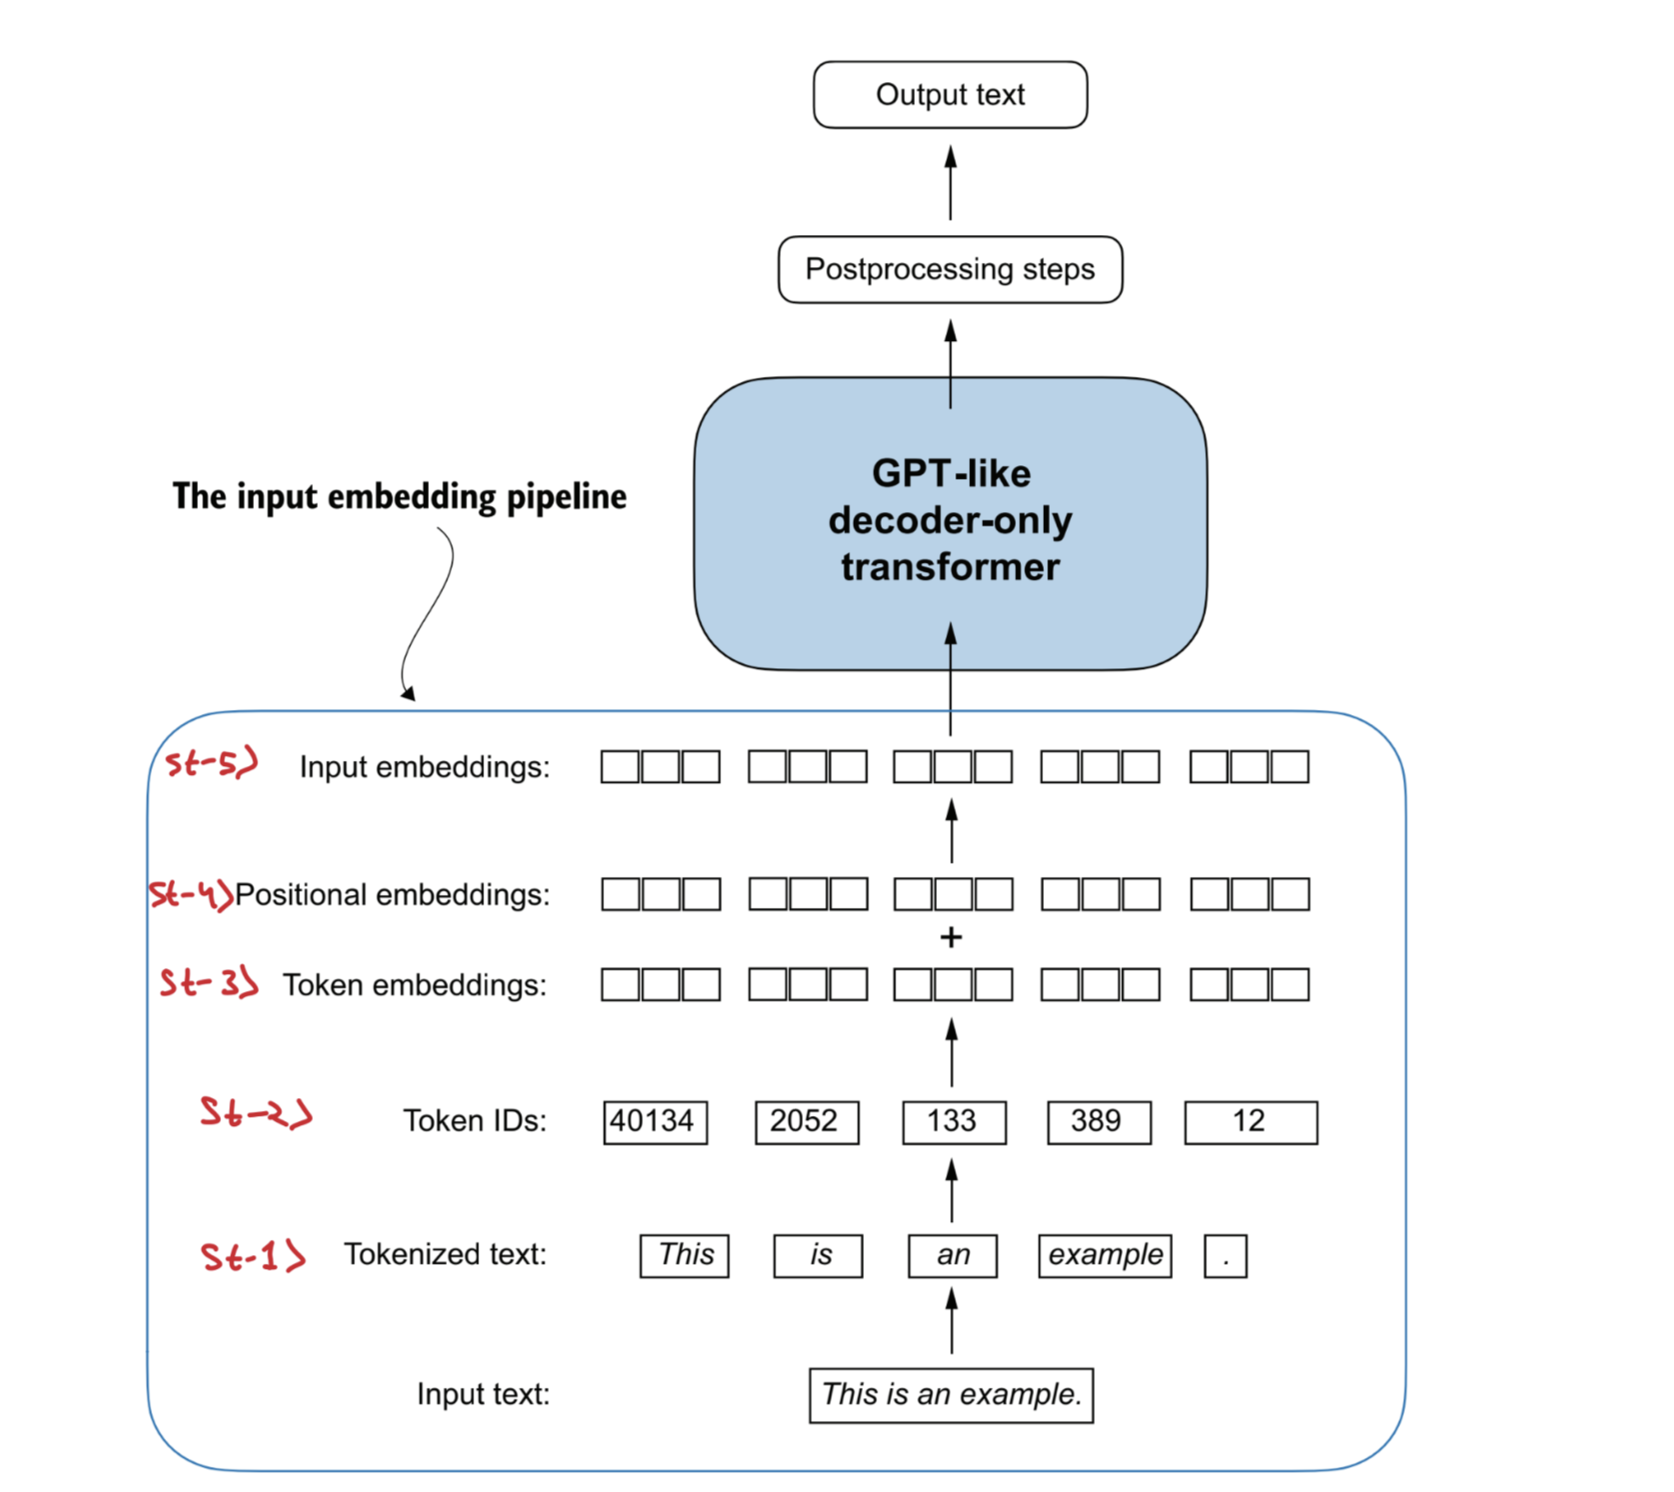

# FINAL: LLM Preprocessing Steps in Encapsulated Form

In [84]:
from torch.utils.data import Dataset, DataLoader
import tiktoken
import os

In [85]:
tokeniz = tiktoken.get_encoding("gpt2")
tokeniz.n_vocab

50257

In [86]:
# LLM Preprocessing function
def preprocessing_data(raw_text,tokenizer,context_length,stride,batch_size,shuffle,drop_last,num_workers):
    # Step-1) Create the dataset
    class GPT2Dataset(Dataset):
        def __init__(self,raw_text,tokenizer,context_length,stride):

            self.inputs = [] # list to store input token ids
            self.targets = [] # list to store ouput token ids
            
            # Step-2) Transform the text to token ids
            token_ids = tokenizer.encode(raw_text,allowed_special = {'<|endoftext|>'})
            # Step-3) Creating the input-target pairs
            for idx in range(0,len(token_ids) - context_length, stride):
                x = token_ids[idx:idx + context_length]  # input 
                y = token_ids[idx + 1: idx + 1 + context_length] # target
                self.inputs.append(torch.tensor(x))
                self.targets.append(torch.tensor(y))


        def __len__(self):  # return the no. of rows in dataset
            return len(self.inputs)

        def __getitem__(self,idx): # return the specific input-target row
            return self.inputs[idx],self.targets[idx]


    # Step-4) Dataloader 

    def gpt2_dataloader(raw_text,tokenizer,context_length,stride,batch_size,shuffle,drop_last , num_workers):

        gpt2_dataset = GPT2Dataset(raw_text = raw_text,tokenizer = tokenizer,
                                   context_length = context_length, stride = stride)

        dataloader = DataLoader(dataset = gpt2_dataset,batch_size = batch_size,
                                shuffle = shuffle, drop_last = drop_last,
                                num_workers = num_workers)

        return dataloader       # return dataloader object


    return gpt2_dataloader(raw_text = raw_text, tokenizer = tokenizer, 
                           context_length = context_length, stride = stride,
                           batch_size = batch_size,shuffle = shuffle,
                           drop_last = drop_last, num_workers = num_workers)


    
    

In [1]:
gpt2_tokenizer = tiktoken.get_encoding("gpt2")
context_length = 512  
stride = context_length // 2
batch_size = 4


dataloader_iter = preprocessing_data(raw_text,tokenizer = gpt2_tokenizer,
                                     context_length = context_length,stride = stride, batch_size = batch_size,
                                     shuffle = False,drop_last = True,
                                     num_workers = os.cpu_count() - 1  ) # Return python iterator 

NameError: name 'tiktoken' is not defined

In [88]:
first_batch = next(dataloader_iter)

TypeError: 'DataLoader' object is not an iterator

In [ ]:
first_batch[0].shape

In [ ]:
batch_cnt = 1
for batch in dataloader_iter:
    print("Batch_cnt:",batch_cnt)
    x,y = batch[0],batch[-1]
    print(f"input shape: {x.shape} | target shape: {y.shape}")
    batch_cnt +=1

In [ ]:
# Step-5) Token Embedding
embd_dim = 64
token_embedding_layer = torch.nn.Embedding(num_embeddings = gpt2_tokenizer.n_vocab,embedding_dim = embd_dim)
positional_embedding_layer = torch.nn.Embedding(num_embeddings = context_length, embedding_dim = embd_dim)

In [ ]:
input_embedding = token_embedding_layer(x) + positional_embedding_layer(torch.arange(context_length))
input_embedding.shape

# HF 1B pretraining Data

In [1]:
from datasets import load_dataset

# Load samples from our collection
finepdfs = load_dataset("codelion/finepdfs-1B", split="train")
dclm = load_dataset("codelion/dclm-baseline-1B", split="train")
fineweb_edu = load_dataset("codelion/fineweb-edu-1B", split="train")

# Mix in 50-30-20 ratio


In [2]:
# Mix in 50-30-20 ratio
from datasets import interleave_datasets
mixed_dataset = interleave_datasets(datasets = [finepdfs,dclm,fineweb_edu],
                                    probabilities = [0.5,0.3,0.2],
                                    seed = 42,
                                    stopping_strategy = "all_exhausted_without_replacement")

In [3]:
mixed_dataset

Dataset({
    features: ['text', 'id', 'dump', 'url', 'date', 'file_path', 'offset', 'token_count', 'language', 'page_average_lid', 'page_average_lid_score', 'full_doc_lid', 'full_doc_lid_score', 'per_page_languages', 'is_truncated', 'extractor', 'page_ends'],
    num_rows: 1930888
})

In [4]:
import tqdm

In [5]:
# # creating a single text file
# pretraining_txt = ""
# for txt in tqdm.tqdm(mixed_dataset,desc = "Concantenating Training Text"):
#     pretraining_txt += txt["text"] + "<|endoftext|>"




In [28]:
!rm /kaggle/working/gpt2_1B_token_pretraining_dataset.txt

In [29]:
from tqdm import tqdm
import time

def main():
    start = time.time()
    grand_total = len(mixed_dataset)
    print(f"Total samples: {grand_total:,}")

    with open("gpt2_1B_token_pretraining_dataset.txt", "w") as f:
        buffer = []
        for sample in tqdm(mixed_dataset, total=grand_total, desc="Writing"):
            buffer.append(sample["text"] + "<|endoftext|>")
            if len(buffer) >= 200000:
                f.write("".join(buffer))
                buffer.clear()
        
        if buffer:
            f.write("".join(buffer))
            buffer.clear()

    elapsed = time.time() - start
    print(f"Done! Total samples: {grand_total:,}")
    print(f"Time taken: {elapsed:.2f}s")

main()

Total samples: 1,930,888


Writing: 100%|██████████| 1930888/1930888 [12:11<00:00, 2641.20it/s] 


Done! Total samples: 1,930,888
Time taken: 737.38s


In [ ]:
with open("/kaggle/working/gpt2_1B_token_pretraining_dataset.txt","r") as f:
    raw_text = f.read()

In [25]:
buff

['How<|endoftext|>', 'are<|endoftext|>', 'you<|endoftext|>']

In [22]:
buff.clear()

In [2]:
import tiktoken

In [3]:
tokenizer = tiktoken.get_encoding("gpt2")

In [4]:
tokenizer.encoding()

50257